# OE2 · Eficiencia de los modelos

Se mide la latencia, los FPS y la memoria de GPU de las nueve corridas y se consolidan con la precisión.

## 1) Comprobar la GPU y conectar Google Drive
Se verifica que haya GPU disponible y se monta Google Drive.

In [1]:
import torch
assert torch.cuda.is_available(), "Activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU (A100)"
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEM_GB = round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1)
print(f"GPU: {GPU_NAME} | {GPU_MEM_GB} GB | torch {torch.__version__}")
if "A100" not in GPU_NAME:
    print("AVISO: no es una A100. Las latencias no serán comparables con el protocolo.")

from google.colab import drive
drive.mount("/content/drive")

GPU: NVIDIA A100-SXM4-40GB | 39.5 GB | torch 2.11.0+cu130
Mounted at /content/drive


## 2) Instalar dependencias
Se instalan las mismas versiones usadas en el entrenamiento.

In [2]:
%pip install -q ultralytics==8.4.113 pycocotools
%pip install -q 'git+https://github.com/facebookresearch/detectron2.git@02b5c4e295e990042a714712c21dc79b731e8833'
import ultralytics, detectron2
print("ultralytics", ultralytics.__version__, "| detectron2", detectron2.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 11.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 14.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 96.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.4/268.4 kB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 15.9 MB/s eta 0:00:00
Cr

## 3) Configuración
Se fija la misma resolución de entrada para los tres modelos.

In [3]:
import os, json, time, shutil, glob, gc, datetime
import numpy as np
import cv2

PROYECTO = "/content/drive/MyDrive/tesis-rg6final"
DATASET = "data_estratificado1"
BASE = os.path.join(PROYECTO, "resultados", "oe2")
SEEDS = [42, 123, 2026]
UMBRALES = [0.001, 0.25]
WARMUP = 10
IOU_YOLO, MAX_DET = 0.70, 300
YOLO_IMGSZ = 1024
D2_MIN_SIZE_TEST, D2_MAX_SIZE_TEST = 768, 1024

ARQS = {
    "yolov11nseg": {"nombre": "YOLOv11n-seg", "tipo": "yolo", "pesos": "yolov11nseg_best.pt"},
    "maskrcnn": {"nombre": "Mask R-CNN (R50-FPN)", "tipo": "d2", "pesos": "maskrcnn_model_best.pth",
                 "yaml": "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml", "tag": "maskrcnn"},
    "cascade": {"nombre": "Cascade Mask R-CNN (R50-FPN)", "tipo": "d2", "pesos": "cascade_maskrcnn_model_best.pth",
                "yaml": "Misc/cascade_mask_rcnn_R_50_FPN_3x.yaml", "tag": "cascade_maskrcnn"},
}
EF_DIR = os.path.join(BASE, "eficiencia")
CONS_DIR = os.path.join(BASE, "consolidado")
INFORME = os.path.join(PROYECTO, "informe_para_codex", "oe2")
for d in (os.path.join(EF_DIR, "latencias"), CONS_DIR, INFORME):
    os.makedirs(d, exist_ok=True)

DATASET_DIR = "/content/datos"
if not os.path.exists(DATASET_DIR):
    shutil.copytree(os.path.join(PROYECTO, DATASET), DATASET_DIR)
with open(os.path.join(DATASET_DIR, "test", "_annotations.coco.json")) as f:
    _gt = json.load(f)
NUM_CLASSES = len(_gt["categories"])
TEST_IMGS = [os.path.join(DATASET_DIR, "test", im["file_name"]) for im in _gt["images"]]
print(f"Test: {len(TEST_IMGS)} fotos | clases: {NUM_CLASSES}")

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = False

faltan = 0
for arq, info in ARQS.items():
    for s in SEEDS:
        w = os.path.join(BASE, arq, f"seed_{s}", info["pesos"])
        print(("OK    " if os.path.exists(w) else "FALTA ") + w)
        faltan += not os.path.exists(w)
print(f"\nCorridas disponibles: {9 - faltan} de 9")

Test: 141 fotos | clases: 2
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/yolov11nseg/seed_42/yolov11nseg_best.pt
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/yolov11nseg/seed_123/yolov11nseg_best.pt
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/yolov11nseg/seed_2026/yolov11nseg_best.pt
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/maskrcnn/seed_42/maskrcnn_model_best.pth
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/maskrcnn/seed_123/maskrcnn_model_best.pth
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/maskrcnn/seed_2026/maskrcnn_model_best.pth
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/cascade/seed_42/cascade_maskrcnn_model_best.pth
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/cascade/seed_123/cascade_maskrcnn_model_best.pth
OK    /content/drive/MyDrive/tesis-rg6final/resultados/oe2/cascade/seed_2026/cascade_maskrcnn_model_best.pth

Corridas disponibles: 9 de 9


## 4) Protocolo de medición
Se define cómo se mide la latencia, igual para los tres modelos.

In [4]:
def ic95_media(x, iters=2000, seed=42):
    x = np.asarray(x, dtype=np.float64)
    rng = np.random.default_rng(seed)
    medias = np.array([rng.choice(x, size=x.size, replace=True).mean() for _ in range(iters)])
    return float(np.percentile(medias, 2.5)), float(np.percentile(medias, 97.5))

@torch.no_grad()
def medir(predecir, imagenes):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    for p in imagenes[:WARMUP]:
        predecir(cv2.imread(p, cv2.IMREAD_COLOR))
    torch.cuda.synchronize()
    tiempos, detecciones = [], []
    for p in imagenes:
        img = cv2.imread(p, cv2.IMREAD_COLOR)
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        n = predecir(img)
        torch.cuda.synchronize()
        tiempos.append((time.perf_counter() - t0) * 1000.0)
        detecciones.append(n)
    t = np.asarray(tiempos)
    lo, hi = ic95_media(t)
    return ({"fps": round(float(1000.0 / t.mean()), 3),
             "lat_p50_ms": round(float(np.percentile(t, 50)), 3),
             "lat_p95_ms": round(float(np.percentile(t, 95)), 3),
             "lat_mean_ms": round(float(t.mean()), 3),
             "lat_ic95_lo": round(lo, 3), "lat_ic95_hi": round(hi, 3),
             "vram_pico_mb": round(float(torch.cuda.max_memory_allocated() / 2**20), 1),
             "det_por_img": round(float(np.mean(detecciones)), 2)}, t.tolist())

def predictor_yolo(pesos, umbral):
    from ultralytics import YOLO
    m = YOLO(pesos)
    def predecir(img):
        r = m.predict(img, imgsz=YOLO_IMGSZ, conf=umbral, iou=IOU_YOLO, max_det=MAX_DET,
                      retina_masks=True, device=0, verbose=False)[0]
        return 0 if r.boxes is None else len(r.boxes)
    return predecir, m.model

def predictor_d2(pesos, yaml_cfg, umbral):
    from detectron2.config import get_cfg
    from detectron2 import model_zoo
    from detectron2.engine import DefaultPredictor
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(yaml_cfg))
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = NUM_CLASSES
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = float(umbral)
    cfg.TEST.DETECTIONS_PER_IMAGE = MAX_DET
    cfg.INPUT.MIN_SIZE_TEST = D2_MIN_SIZE_TEST
    cfg.INPUT.MAX_SIZE_TEST = D2_MAX_SIZE_TEST
    cfg.MODEL.WEIGHTS = pesos
    cfg.MODEL.DEVICE = "cuda"
    pred = DefaultPredictor(cfg)
    return (lambda img: len(pred(img)["instances"])), pred.model

## 5) Medir las corridas
Se mide la latencia de cada corrida en la misma GPU.

In [5]:
import pandas as pd

filas = []
for arq, info in ARQS.items():
    for s in SEEDS:
        w = os.path.join(BASE, arq, f"seed_{s}", info["pesos"])
        if not os.path.exists(w):
            print(f"[{arq} semilla {s}] sin pesos: se omite")
            continue
        for u in UMBRALES:
            if info["tipo"] == "yolo":
                predecir, red = predictor_yolo(w, u)
            else:
                predecir, red = predictor_d2(w, info["yaml"], u)
            r, latencias = medir(predecir, TEST_IMGS)
            filas.append({"arq": arq, "arquitectura": info["nombre"], "seed": s, "umbral": u, **r,
                          "params_millones": round(sum(p.numel() for p in red.parameters()) / 1e6, 3),
                          "tamano_mb": round(os.path.getsize(w) / 2**20, 2),
                          "n_imagenes": len(TEST_IMGS), "gpu": GPU_NAME, "gpu_mem_gb": GPU_MEM_GB})
            with open(os.path.join(EF_DIR, "latencias", f"{arq}_seed{s}_thr{u}.json"), "w") as f:
                json.dump(latencias, f)
            print(f"[{arq} semilla {s} umbral {u}] p50={r['lat_p50_ms']} ms | FPS={r['fps']} | "
                  f"VRAM={r['vram_pico_mb']} MB | det/img={r['det_por_img']}")
            del predecir, red
            gc.collect()
            torch.cuda.empty_cache()

df_ef = pd.DataFrame(filas)
df_ef.to_csv(os.path.join(EF_DIR, "eficiencia_por_corrida.csv"), index=False)
with open(os.path.join(EF_DIR, "eficiencia_por_corrida.json"), "w") as f:
    json.dump(filas, f, indent=2)
print(f"\nGuardado: {len(filas)} mediciones en {EF_DIR}")

[yolov11nseg semilla 42 umbral 0.001] p50=19.868 ms | FPS=45.047 | VRAM=915.0 MB | det/img=11.94
[yolov11nseg semilla 42 umbral 0.25] p50=19.144 ms | FPS=50.868 | VRAM=271.1 MB | det/img=5.16
[yolov11nseg semilla 123 umbral 0.001] p50=20.145 ms | FPS=47.54 | VRAM=1008.7 MB | det/img=15.76
[yolov11nseg semilla 123 umbral 0.25] p50=19.147 ms | FPS=50.899 | VRAM=272.8 MB | det/img=5.55
[yolov11nseg semilla 2026 umbral 0.001] p50=19.838 ms | FPS=47.939 | VRAM=656.8 MB | det/img=15.16
[yolov11nseg semilla 2026 umbral 0.25] p50=18.845 ms | FPS=51.639 | VRAM=271.0 MB | det/img=5.29


/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1020 15:57:03.304000 574 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


[maskrcnn semilla 42 umbral 0.001] p50=62.177 ms | FPS=13.233 | VRAM=3952.5 MB | det/img=30.77
[maskrcnn semilla 42 umbral 0.25] p50=57.338 ms | FPS=14.901 | VRAM=1677.3 MB | det/img=6.64
[maskrcnn semilla 123 umbral 0.001] p50=59.757 ms | FPS=13.544 | VRAM=4051.9 MB | det/img=31.06
[maskrcnn semilla 123 umbral 0.25] p50=57.358 ms | FPS=15.138 | VRAM=1677.3 MB | det/img=6.74
[maskrcnn semilla 2026 umbral 0.001] p50=59.561 ms | FPS=14.186 | VRAM=3937.3 MB | det/img=31.4
[maskrcnn semilla 2026 umbral 0.25] p50=57.113 ms | FPS=15.208 | VRAM=1567.6 MB | det/img=6.67
[cascade semilla 42 umbral 0.001] p50=68.664 ms | FPS=12.552 | VRAM=4160.7 MB | det/img=32.09
[cascade semilla 42 umbral 0.25] p50=66.33 ms | FPS=13.349 | VRAM=1631.7 MB | det/img=6.58
[cascade semilla 123 umbral 0.001] p50=68.496 ms | FPS=12.566 | VRAM=4046.1 MB | det/img=30.81
[cascade semilla 123 umbral 0.25] p50=66.252 ms | FPS=13.307 | VRAM=1631.7 MB | det/img=6.44
[cascade semilla 2026 umbral 0.001] p50=69.045 ms | FPS=12

## 6) Consolidar precisión y eficiencia
Se calculan medias y desviaciones y se dibuja el frente de Pareto.

PRECISIÓN (media ± desviación, test n=141, conf 0.001):
                arquitectura  n_semillas  map_segm_50_95_mean  map_segm_50_95_std  map_bbox_50_95_mean  map_bbox_50_95_std
Cascade Mask R-CNN (R50-FPN)           3               64.126               0.179               63.371               0.075
        Mask R-CNN (R50-FPN)           3               63.158               0.195               60.473               0.700
                YOLOv11n-seg           3               61.162               0.814               70.480               0.654

EFICIENCIA (media ± desviación, misma sesión y GPU):
                arquitectura  umbral  n_semillas  lat_p50_ms_mean  lat_p50_ms_std  fps_mean  vram_pico_mb_mean  det_por_img_mean
Cascade Mask R-CNN (R50-FPN)   0.001           3           68.735           0.281    12.536           3948.700            31.610
Cascade Mask R-CNN (R50-FPN)   0.250           3           66.326           0.072    13.324           1631.700             6.537
        Mas

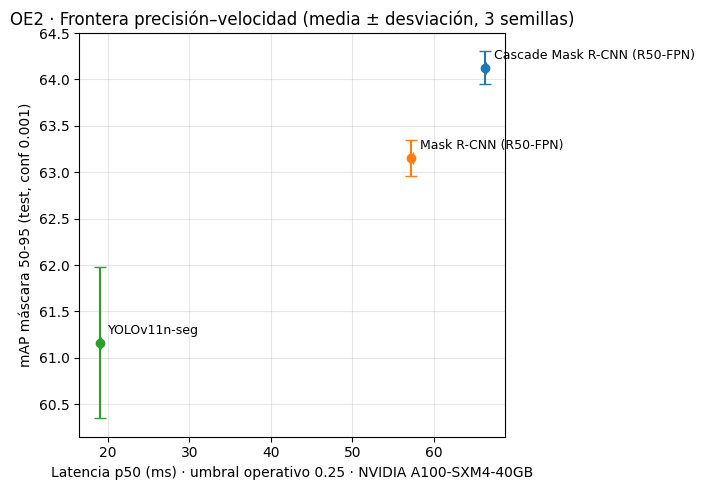


Guardado en /content/drive/MyDrive/tesis-rg6final/resultados/oe2/consolidado : ['pareto_precision_velocidad.png', 'precision_por_corrida.csv', 'run_manifest.json', 'tabla_eficiencia.csv', 'tabla_precision.csv']


In [6]:
import matplotlib.pyplot as plt

prec = []
for arq, info in ARQS.items():
    for s in SEEDS:
        carpeta = os.path.join(BASE, arq, f"seed_{s}", "reportes")
        ruta = os.path.join(carpeta, "obj2_results_all_models.json")
        if not os.path.exists(ruta):
            continue
        with open(ruta) as f:
            fila_rep = json.load(f)[-1]
        fila = {"arq": arq, "arquitectura": info["nombre"], "seed": s}
        for k in ("map_bbox_50_95", "ap50_bbox", "ap75_bbox", "map_segm_50_95", "ap50_segm", "ap75_segm"):
            fila[k] = float(fila_rep[k])
        por_clase = glob.glob(os.path.join(carpeta, "*per_class_ap.json"))
        if por_clase:
            with open(por_clase[0]) as f:
                pc = json.load(f)
            escala = 100.0 if info["tipo"] == "d2" else 1.0
            for tipo in ("segm", "bbox"):
                for clase, v in pc[tipo].items():
                    fila[f"ap_{tipo}_{clase}"] = round(float(v["AP"]) * escala, 3)
        prec.append(fila)
df_p = pd.DataFrame(prec)
df_p.to_csv(os.path.join(CONS_DIR, "precision_por_corrida.csv"), index=False)

def media_sd(df, claves, metricas):
    g = df.groupby(claves)
    out = g[metricas].agg(["mean", "std"]).round(3)
    out.columns = [f"{m}_{e}" for m, e in out.columns]
    out["n_semillas"] = g.size()
    return out.reset_index()

tab_p = media_sd(df_p, ["arq", "arquitectura"], [c for c in df_p.columns if c.startswith(("map_", "ap"))])
tab_p.to_csv(os.path.join(CONS_DIR, "tabla_precision.csv"), index=False)
tab_e = media_sd(df_ef, ["arq", "arquitectura", "umbral"],
                 ["fps", "lat_p50_ms", "lat_p95_ms", "lat_mean_ms", "vram_pico_mb", "det_por_img"])
tab_e.to_csv(os.path.join(CONS_DIR, "tabla_eficiencia.csv"), index=False)

print(f"PRECISIÓN (media ± desviación, test n={len(TEST_IMGS)}, conf 0.001):")
print(tab_p[["arquitectura", "n_semillas", "map_segm_50_95_mean", "map_segm_50_95_std",
             "map_bbox_50_95_mean", "map_bbox_50_95_std"]].to_string(index=False))
print("\nEFICIENCIA (media ± desviación, misma sesión y GPU):")
print(tab_e[["arquitectura", "umbral", "n_semillas", "lat_p50_ms_mean", "lat_p50_ms_std",
             "fps_mean", "vram_pico_mb_mean", "det_por_img_mean"]].to_string(index=False))

op = tab_e[tab_e["umbral"] == 0.25].merge(tab_p, on=["arq", "arquitectura"])
fig, ax = plt.subplots(figsize=(7, 5))
for _, r in op.iterrows():
    ax.errorbar(r["lat_p50_ms_mean"], r["map_segm_50_95_mean"],
                xerr=r["lat_p50_ms_std"], yerr=r["map_segm_50_95_std"], fmt="o", capsize=4)
    ax.annotate(r["arquitectura"], (r["lat_p50_ms_mean"], r["map_segm_50_95_mean"]),
                textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set_xlabel("Latencia p50 (ms) · umbral operativo 0.25 · " + GPU_NAME)
ax.set_ylabel("mAP máscara 50-95 (test, conf 0.001)")
ax.set_title("OE2 · Frontera precisión–velocidad (media ± desviación, 3 semillas)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(CONS_DIR, "pareto_precision_velocidad.png"), dpi=200)
plt.show()

import importlib.metadata as metadata
def version(paquete):
    try:
        return metadata.version(paquete)
    except Exception:
        return None
with open(os.path.join(CONS_DIR, "run_manifest.json"), "w") as f:
    json.dump({"fecha_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
               "gpu": GPU_NAME, "gpu_mem_gb": GPU_MEM_GB, "dataset": DATASET,
               "versiones": {p: version(p) for p in ("torch", "torchvision", "ultralytics", "detectron2",
                                                     "pycocotools", "numpy")},
               "semillas": SEEDS, "umbrales": UMBRALES, "warmup": WARMUP,
               "resolucion": {"yolo_imgsz": YOLO_IMGSZ, "d2_min_size_test": D2_MIN_SIZE_TEST,
                              "d2_max_size_test": D2_MAX_SIZE_TEST},
               "corridas_precision": len(df_p), "mediciones_eficiencia": len(df_ef),
               "tf32": True, "cudnn_benchmark": False}, f, indent=2)
print("\nGuardado en", CONS_DIR, ":", sorted(os.listdir(CONS_DIR)))

## 7) Guardar los resultados
Se guardan las tablas y figuras finales.

In [7]:
for archivo in ("tabla_precision.csv", "tabla_eficiencia.csv", "precision_por_corrida.csv",
                "pareto_precision_velocidad.png", "run_manifest.json"):
    shutil.copy2(os.path.join(CONS_DIR, archivo), INFORME)
shutil.copy2(os.path.join(EF_DIR, "eficiencia_por_corrida.csv"), INFORME)

tags = {"yolov11nseg": "yolov11seg_phaseA", "maskrcnn": "maskrcnn_phaseA", "cascade": "cascade_maskrcnn_phaseA"}
for arq in ARQS:
    for s in SEEDS:
        origen = os.path.join(BASE, arq, f"seed_{s}", "reportes", f"confusion_{tags[arq]}")
        if os.path.isdir(origen):
            destino = os.path.join(INFORME, "matrices_confusion", f"{arq}_seed{s}")
            os.makedirs(destino, exist_ok=True)
            for archivo in ("confusion_matrix.png", "confusion_summary.json"):
                shutil.copy2(os.path.join(origen, archivo), destino)

def tabla_md(df):
    lineas = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lineas += ["| " + " | ".join(str(x) for x in fila) + " |" for fila in df.itertuples(index=False)]
    return "\n".join(lineas)

t_prec = tab_p[["arquitectura", "n_semillas", "map_segm_50_95_mean", "map_segm_50_95_std", "ap50_segm_mean",
                "map_bbox_50_95_mean", "map_bbox_50_95_std"]].round(2)
t_ef = tab_e[["arquitectura", "umbral", "lat_p50_ms_mean", "lat_p50_ms_std", "lat_p95_ms_mean", "fps_mean",
              "vram_pico_mb_mean", "det_por_img_mean"]].round(2)
t_ef["umbral"] = tab_e["umbral"]
resumen = f'''# OE2 · Benchmark de precisión y velocidad (FASE A)

**Modelos:** YOLOv11n-seg (Ultralytics 8.4.113), Mask R-CNN R50-FPN y Cascade Mask R-CNN R50-FPN (Detectron2 @02b5c4e).
**Datos:** {DATASET} (data_curado estratificado 70/20/10); test de {len(TEST_IMGS)} fotos. Semillas 42, 123 y 2026.

**Protocolo común:** mismos splits (auditados por MD5), misma resolución efectiva (YOLO imgsz 1024; Detectron2 lado
corto 768 / máximo 1024), 50 épocas, aumento CommonAug A (volteo horizontal, color, rotación ±5°) y el mismo
evaluador (pycocotools COCOeval, conf 0.001, 300 detecciones, máscaras RLE a resolución original, AP 0-100).
YOLO: batch 16, optimizador auto (AdamW lr 0.001667), cos_lr. Detectron2: lote 8, BASE_LR 0.0005, pasos al 70/90 %,
mejor modelo según segm/AP en valid.

**Eficiencia:** {GPU_NAME}, misma sesión para las 9 corridas, lote 1, de extremo a extremo, 10 de calentamiento,
lectura de imagen fuera del cronómetro; umbrales 0.001 (protocolo) y 0.25 (operativo).

## Precisión (media y desviación entre semillas)

{tabla_md(t_prec)}

## Eficiencia (media entre semillas)

{tabla_md(t_ef)}

Archivos: tabla_precision.csv, tabla_eficiencia.csv, precision_por_corrida.csv, eficiencia_por_corrida.csv,
pareto_precision_velocidad.png, matrices_confusion/<modelo>_seed<N>/ (umbral 0.25, IoU de máscara 0.5),
run_manifest.json (versiones y GPU). Resultados completos: resultados/oe2/.
'''
with open(os.path.join(INFORME, "resumen.md"), "w", encoding="utf-8") as f:
    f.write(resumen)
print("Resultados del OE2 copiados a", INFORME)

Resultados del OE2 copiados a /content/drive/MyDrive/tesis-rg6final/informe_para_codex/oe2
